# 01 · Modelo pub/sub y protocolo MQTT

[Índice MQTT](00_indice_mqtt.ipynb) · [Anterior](00_indice_mqtt.ipynb) · [Siguiente](02_broker_mosquitto_y_red.ipynb)

## MQTT, TCP y los datos de aplicación

TCP proporciona un flujo de bytes ordenado entre dos conexiones de red. El sistema distingue el puerto de escucha del broker, por ejemplo 1883, del puerto efímero de salida que asigna el sistema operativo al cliente. Sobre ese socket, MQTT define mensajes de control con un encabezado fijo, un encabezado variable según el tipo de paquete y, donde corresponde, un payload. Un paquete MQTT puede abarcar varios segmentos TCP, y un segmento TCP puede llevar varios paquetes MQTT. El límite entre paquetes lo interpreta la biblioteca MQTT.

En 3.1.1, el cliente comienza enviando CONNECT y el broker responde CONNACK. Publicar y suscribirse son acciones independientes: SUBSCRIBE pide filtros, SUBACK confirma cuáles fueron concedidos y PUBLISH lleva un tema concreto y el payload. Las conexiones son bidireccionales y suelen permanecer abiertas. Con keepalive, el cliente usa otros paquetes de control o PINGREQ para mostrar actividad y recibe PINGRESP ante un ping. La especificación define cuándo el broker considera vencida la conexión por ausencia de tráfico. [OASIS MQTT 3.1.1, §2–3](https://docs.oasis-open.org/mqtt/mqtt/v3.1.1/os/mqtt-v3.1.1-os.html)

**Tema** es la clave de encaminamiento. **Payload** es contenido de aplicación y puede ser texto o binario. En MonitorAire se acuerda JSON, CSV o texto plano según el tema. Mosquitto encamina esos bytes por el tema, mientras Python comprueba sus valores.

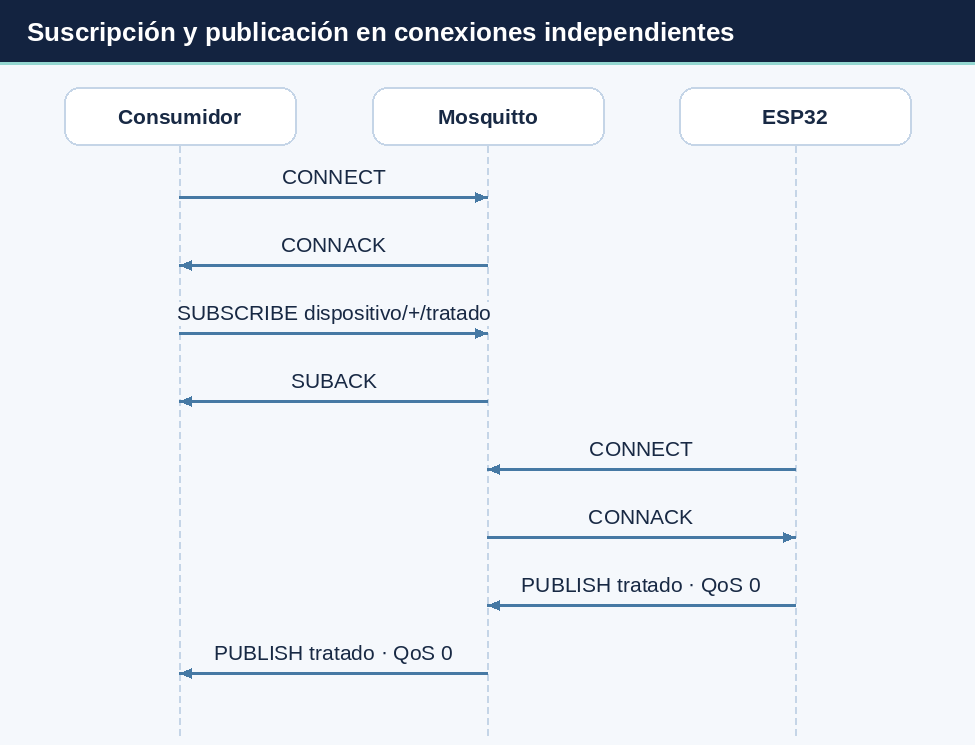

## Publicación y suscripción

Un publicador conoce el broker y el tema; muchos consumidores pueden suscribirse simultáneamente. El broker entrega una copia a cada suscripción pertinente. Este desacoplamiento permite inspeccionar tráfico con `mosquitto_sub` mientras Python procesa las lecturas. Para recibir eventos futuros, el observador establece su propia conexión y se suscribe antes de publicar la prueba.

Los nombres distinguen mayúsculas y minúsculas. `/` separa niveles. `+` en un filtro ocupa un nivel completo; `#` ocupa los niveles restantes y, cuando se usa, va al final como nivel completo. Un nombre de tema en PUBLISH es literal y carece de comodines. Entre filtros atendidos por MQTT, la aplicación puede imponer un contrato más estricto. [OASIS MQTT 3.1.1, §4.7](https://docs.oasis-open.org/mqtt/mqtt/v3.1.1/os/mqtt-v3.1.1-os.html)

| Filtro | Coincide | Queda fuera |
| --- | --- | --- |
| `dispositivo/+/tratado` | `dispositivo/ESP32_S3_0001/tratado` | `dispositivo/ESP32_S3_0001/crudo` |
| `dispositivo/ESP32_S3_0001/#` | Los temas de esa placa, incluidos sus descendientes | El tema de otra placa |
| `dispositivo/+/estado` | El estado de cualquier ID de un nivel | `dispositivo/zona/placa/estado` |

Los comodines se pasan entre comillas en un shell. El backend restringe todavía más la estructura de los temas de telemetría y espera tres niveles definidos.

## QoS y alcance de la confirmación

| QoS | Intercambio | Consecuencia |
| --- | --- | --- |
| 0 | PUBLISH. | El protocolo no solicita confirmación de ese paquete. Una pérdida puede dejar al receptor sin la lectura. |
| 1 | PUBLISH con identificador de paquete y PUBACK. | Entrega al menos una vez en el intercambio sujeto a las operaciones de sesión y reconexión. Los reenvíos pueden duplicar la entrega. |
| 2 | PUBLISH, PUBREC, PUBREL y PUBCOMP. | El protocolo añade estados intermedios para efectuar una entrega exactamente una vez entre esos dos extremos. |

El recorrido publicador→broker y el recorrido broker→suscriptor son intercambios separados. Suscribirse con QoS 1 permite recibir en QoS 1 publicaciones que lo admiten; una lectura publicada con QoS 0 sigue llegando en QoS 0. Aunque un broker confirme un PUBLISH, eso indica la recepción en ese enlace, y el suscriptor conserva su propio ciclo. La aplicación decide qué significa completar el trabajo, por ejemplo cuando termina un INSERT en PostgreSQL. [OASIS MQTT 3.1.1, §3.3–3.7 y §4.3](https://docs.oasis-open.org/mqtt/mqtt/v3.1.1/os/mqtt-v3.1.1-os.html)

PubSubClient publica en QoS 0 y acepta suscripciones QoS 0 o 1. El firmware publica actualizaciones y CSV con QoS 0, solicita la suscripción a `ack` en QoS 1 y configura el Last Will en QoS 1. Paho publica en QoS 1 la lectura que resulta de convertir una fila y el mensaje de aplicación `ack`. El identificador de paquete usado por MQTT se gestiona por sesión, mientras que el identificador del registro viaja en el CSV y sobrevive a los reintentos de la aplicación. [Limitaciones de PubSubClient](https://github.com/knolleary/pubsubclient#limitations) · [Cliente Paho](https://eclipse.dev/paho/files/paho.mqtt.python/html/client.html)

## Sesión, keepalive y reconexión

**Client ID** identifica una sesión ante el broker. La placa usa `DEVICE_ID` y el backend toma `MQTT_CLIENT_ID` o `monitor-aire-dashboard`. Con un mismo ID compartido, el broker reemplaza la conexión anterior al aceptar la nueva. Dos consumidores con IDs distintos y filtros iguales reciben copias, cada uno según su suscripción. El nombre del tema no asigna ni autentica la sesión.

Una **sesión limpia** empieza sin suscripciones anteriores y el cliente vuelve a suscribirse al conectar. En una sesión persistente, el broker puede recuperar suscripciones y mensajes pendientes de QoS 1/2 atendiendo a las condiciones del estándar. El proyecto usa los valores predeterminados de sesión limpia de las bibliotecas, restablece suscripciones al conectar y conserva históricos mediante LittleFS y PostgreSQL. El firmware intenta volver a conectar aproximadamente cada 5 s cuando puede; el cliente integrado usa la reconexión de Paho con espera creciente de 1 a 30 s. Los **60 s de keepalive** de Python y los **15 s predeterminados** de PubSubClient son temporizadores de detección de inactividad, distintos del intervalo de reintento. La disponibilidad observada por el backend cambia cuando llega un SUBACK exitoso o cuando Paho informa de desconexión. [Sesiones y keepalive, OASIS MQTT 3.1.1, §3.1.2](https://docs.oasis-open.org/mqtt/mqtt/v3.1.1/os/mqtt-v3.1.1-os.html) · [API de Paho](https://eclipse.dev/paho/files/paho.mqtt.python/html/client.html) · [Valores de PubSubClient](https://github.com/knolleary/pubsubclient#limitations)

## Retain y Last Will

**Retain** solicita al broker guardar el último mensaje retenido de un tema y entregarlo a clientes que se suscriban posteriormente. Si el mismo tema recibe una nueva publicación retenida, sustituye el valor anterior. El firmware usa esto para `dispositivo/<id>/estado`, así un observador que acaba de conectarse recibe el último estado disponible. `crudo`, `tratado` y `ack` se publican sin retain y circulan como eventos.

**Last Will** es un mensaje que el cliente registra en CONNECT. Si la conexión se pierde sin un DISCONNECT válido, el broker puede emitir el testamento según las reglas de MQTT, normalmente tras detectar el cierre del socket o agotar el keepalive. El ESP32 registra `desconectado` como testamento retenido en QoS 1 y, tras conectarse y enviar su petición de suscripción al ACK, publica `conectado` retenido. El indicador basado en este tema puede tardar en cambiar si el corte todavía no se ha detectado. Una desconexión MQTT ordenada suprime el testamento. Si cae el broker, el API distingue la pérdida de ese enlace y deja de usar los estados anteriores en memoria. [OASIS MQTT 3.1.1, §3.1.2, §3.3.1 y §3.14](https://docs.oasis-open.org/mqtt/mqtt/v3.1.1/os/mqtt-v3.1.1-os.html)

**Preguntas de revisión.** ¿Por qué QoS 1 en `mosquitto_sub` no convierte en QoS 1 el envío de la placa? ¿Qué evidencia añade un ACK de aplicación después de PUBACK? ¿Qué valor debería ver un nuevo suscriptor de estado después de que el broker emita el Last Will?

[Índice MQTT](00_indice_mqtt.ipynb) · [Anterior](00_indice_mqtt.ipynb) · [Siguiente](02_broker_mosquitto_y_red.ipynb)